# Anomalib 사용법 입문 · PatchCore

정상 이미지로 **PatchCore**를 학습하고, 새로운 이미지의 이상 여부와 위치를 찾아보자.

이 노트북은 **실행 환경과 데이터가 없는 Windows PC**에서 시작한다. Python 설치부터 데이터 다운로드, 학습, 평가, 추론, 모델 저장까지 순서대로 진행한다. 학습에 필요한 코드는 노트북 안에 있으며, 별도 프로젝트 파일을 가져올 필요가 없다.

| 실습 | 데이터 | 배우는 API |
|---|---|---|
| 공개 데이터 실습 | MVTec AD의 `bottle` | `MVTecAD`로 표준 데이터 읽기 |
| 사용자 데이터 실습 | `hazelnut_toy` | `Folder`로 내 이미지 폴더 연결하기 |

두 실습 모두 `데이터 → PatchCore → Engine.fit/test/predict`라는 같은 흐름을 사용한다.


## 실행 준비 · 처음 한 번

### Python과 Jupyter 설치

1. [Python 3.11 Windows 설치 파일](https://www.python.org/downloads/release/python-3119/)로 Python을 설치한다. 설치할 때 **Python Launcher**를 포함한다.
2. PowerShell을 열고 아래 명령을 순서대로 실행한다. 영문 경로인 `C:\anomalib_lab`을 사용한다.

```powershell
mkdir C:\anomalib_lab
cd C:\anomalib_lab
py -3.11 -m venv .venv
.\.venv\Scripts\python -m pip install --upgrade pip
.\.venv\Scripts\python -m pip install torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cu121
.\.venv\Scripts\python -m pip install anomalib==2.2.0 lightning==2.5.5 pytorch-lightning==2.5.5 torchmetrics==1.8.2 timm==1.0.20 huggingface_hub==0.34.4 pandas==2.2.3 scikit-learn==1.6.1 jupyterlab ipywidgets
.\.venv\Scripts\python -m jupyter lab
```

위 PyTorch 명령은 **NVIDIA GPU가 있는 Windows PC**용이다. GPU가 없으면 해당 명령의 URL 끝 `cu121`을 `cpu`로 바꾼다. CUDA Toolkit을 별도로 설치할 필요는 없으며, GPU를 사용하려면 호환되는 NVIDIA 드라이버가 있어야 한다.

Jupyter가 열리면 이 노트북을 업로드하고 **Python 3 (ipykernel)** 커널을 선택한다. 방금 만든 가상환경의 Jupyter에서 열어야 한다. VS Code에서는 `C:\anomalib_lab\.venv\Scripts\python.exe`를 커널로 선택한다. 설치 후에는 커널을 재시작하고 아래 셀부터 실행한다.

### 실습에 필요한 다운로드

최초 실행에는 인터넷이 필요하다. PyTorch와 패키지 설치에 수 GB의 공간이 필요하며, 아래에서 MVTec AD의 bottle 범주, 약 6.4MB의 hazelnut_toy, ResNet18 사전학습 가중치를 내려받는다. 이미 받은 데이터는 재사용한다. 실습 결과는 `C:/anomalib_lab/results/patchcore_usage`에 저장한다.


In [1]:
from pathlib import Path
from importlib.metadata import version

import torch
import pandas as pd
from lightning.pytorch import seed_everything
from huggingface_hub import snapshot_download
from anomalib.data import MVTecAD, Folder
from anomalib.data.utils import DownloadInfo, download_and_extract
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.visualization import visualize_image_item
from IPython.display import display

DATA = Path('C:/anomalib_lab/datasets')
RESULTS = Path('C:/anomalib_lab/results/patchcore_usage')
DATA.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
seed_everything(42)

print('Anomalib:', version('anomalib'), '/ PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU 사용')


Seed set to 42


Anomalib: 2.2.0 / PyTorch: 2.5.1+cpu
GPU: CPU 사용


### Windows에서 결과 폴더 만들기

Anomalib 2.2.0은 결과 폴더에 심볼릭 링크를 만들려고 한다. 아래의 짧은 `NotebookEngine`은 이를 일반 폴더로 바꿔 관리자 권한 없이 실행하게 한다. 학습·평가·추론은 Anomalib의 `Engine` 기능을 그대로 사용한다. 이 셀은 한 번 실행하고 이후에는 `fit`, `test`, `predict`의 사용법에 집중한다.


In [2]:
class NotebookEngine(Engine):
    def _setup_workspace(self, *args, **kwargs):
        kwargs['versioned_dir'] = False
        return super()._setup_workspace(*args, **kwargs)


## 1. MVTec AD 데이터 내려받기

MVTec AD는 정상 제품과 여러 결함의 이미지·정답 마스크를 제공한다. 여기서는 병의 파손과 오염을 검사하는 **bottle** 범주만 사용한다.

설치 버전의 기본 다운로드 주소가 동작하지 않아, 아래에서는 고정 버전의 [공개 미러](https://huggingface.co/datasets/foersben/mvtec-ad/tree/28afa1599de4e2214db952d6f5475138934d084c/bottle)에서 bottle 폴더를 받는다. 이 미러는 MVTec의 공식 배포처와 구분하며, 원본 MVTec AD의 **CC BY-NC-SA 4.0** 조건을 따른다.

`snapshot_download`는 저장소의 파일을 폴더로 내려받는다. `allow_patterns='bottle/**'`는 필요한 범주만 선택하고, `revision`은 같은 자료를 받도록 버전을 고정한다.


In [3]:
snapshot_download(
    repo_id='foersben/mvtec-ad',
    repo_type='dataset',
    revision='28afa1599de4e2214db952d6f5475138934d084c',
    allow_patterns='bottle/**',
    local_dir=DATA / 'MVTecAD',
)
print('준비된 폴더:', DATA / 'MVTecAD/bottle')


Fetching 357 files:   0%|          | 0/357 [00:00<?, ?it/s]

준비된 폴더: C:/anomalib_lab/datasets/MVTecAD/bottle


## 2. MVTecAD로 학습·검증·시험 데이터 읽기

데이터는 다음 구조를 가진다. `root`에는 `bottle`의 **상위 폴더**를 지정한다.

```text
datasets/MVTecAD/bottle/
├── train/good/                 정상 학습 이미지
├── test/good/                  정상 평가 이미지
├── test/broken_large/          큰 파손
├── test/broken_small/          작은 파손
├── test/contamination/         오염
└── ground_truth/<결함 종류>/    이상 영역 정답 마스크
```

`MVTecAD`는 이 구조를 알고 있으므로 이미지와 마스크를 직접 연결할 필요가 없다. `val_split_mode='from_test'`는 공식 test를 검증과 시험으로 나눈다. 검증 데이터는 임계값을 정할 때, 시험 데이터는 성능을 측정할 때 사용한다. 정상 학습 데이터는 그대로 유지한다.

`seed=42`는 분할의 난수 출발점을 고정하고, `num_workers=0`은 Windows Jupyter에서 데이터 읽기를 단순하게 한다. batch size는 한 번에 처리할 이미지 수다. 이번 분할은 수업용이며 공식 test 전체를 평가하는 벤치마크와 구분한다.


In [4]:
mvtec_data = MVTecAD(
    root=DATA / 'MVTecAD',
    category='bottle',
    train_batch_size=4,
    eval_batch_size=4,
    num_workers=0,
    val_split_mode='from_test',
    val_split_ratio=0.5,
    seed=42,
)
mvtec_data.setup()

pd.Series({
    '정상 학습 이미지': len(mvtec_data.train_data),
    '검증 이미지': len(mvtec_data.val_data),
    '시험 이미지': len(mvtec_data.test_data),
}, name='MVTec AD 영상 수')


정상 학습 이미지    209
검증 이미지        41
시험 이미지        42
Name: MVTec AD 영상 수, dtype: int64

## 3. PatchCore 생성하고 학습하기

PatchCore는 사전학습 CNN에서 정상 이미지의 **작은 영역별 특징**을 추출해 메모리 뱅크에 저장한다. 새로운 이미지의 특징이 저장된 정상 특징과 멀수록 이상 점수가 커진다.

- `backbone='resnet18'`: 특징을 추출할 CNN. 노트북 PC의 메모리 사용량을 줄인다.
- `coreset_sampling_ratio=0.01`: 정상 특징 중 대표적인 1%를 메모리에 남긴다.
- `configure_pre_processor(image_size=(128,128))`: 입력 크기를 맞추고 ImageNet 정규화를 적용한다. 학습·추론에 같은 전처리를 사용한다.
- `visualizer=False`: 전체 시험 영상의 자동 저장을 생략하고, 뒤의 Anomalib 내장 시각화 함수로 선택한 예측을 표시한다.

`Engine.fit`이 정상 특징을 수집하고 검증 데이터의 결과로 점수 정규화와 판정 임계값을 정한다. 검증 라벨은 이 보정에 사용되므로, 이 예제는 **라벨이 있는 검증 데이터로 보정하는 파이프라인**이다. PatchCore는 역전파로 가중치를 반복 학습하는 모델이 아니며, 정상 특징을 한 번 수집한다. 학습 손실 곡선이 없어도 정상 동작이다.


In [5]:
mvtec_model = Patchcore(
    backbone='resnet18',
    coreset_sampling_ratio=0.01,
    pre_processor=Patchcore.configure_pre_processor(image_size=(128, 128)),
    visualizer=False,
)
mvtec_engine = NotebookEngine(default_root_dir=RESULTS / 'mvtecad')
mvtec_engine.fit(model=mvtec_model, datamodule=mvtec_data)


/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:210: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


HPU available: False, using: 0 HPUs


/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:751: Checkpoint directory /home/claude/w11/C:/anomalib_lab/results/patchcore_usage/mvtecad/Patchcore/MVTecAD/bottle/latest/weights/lightning exists and is not empty.
/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer

  | Name           | Type           | Params | Mode 
----------------------------------------------------------
0 | pre_processor  | PreProcessor   | 0      | train
1 | post_processor | PostProcessor  | 0      | train
2 | evaluator      | Evaluator      | 0      | train
3 | model          | PatchcoreModel | 2.8 M  | train
----------------------------------------------------------
2.8 M     Trainable params
0         Non-trainable params
2.8 M     Total params
11.131    Total estimated model params size (MB)
19        Modules in train mode
69     

/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:527: Found 69 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


... (20 outputs left out)

Selecting Coreset Indices.:  91%|█████████ | 488/535 [00:01<00:00, 264.44it/s]

Selecting Coreset Indices.:  96%|█████████▋| 515/535 [00:01<00:00, 255.72it/s]

Selecting Coreset Indices.: 100%|██████████| 535/535 [00:02<00:00, 256.68it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.


## 4. test로 성능 확인하기

`test`는 시험 영상의 정답과 예측을 비교해 지표를 계산한다. 검증으로 정한 임계값은 유지한다.

| 지표 | 의미 |
|---|---|
| `image_AUROC` | 이미지 단위의 정상·이상 구분 능력 |
| `image_F1Score` | 현재 이미지 판정 임계값에서 정밀도와 재현율의 조화평균 |
| `pixel_AUROC` | 픽셀 단위의 정상·이상 구분 능력 |
| `pixel_F1Score` | 현재 픽셀 임계값에서 예측 영역과 정답 영역의 일치 정도 |

각 지표는 클수록 좋다. AUROC는 점수의 순위를, F1은 현재 임계값의 판정을 평가하므로 서로 다른 질문에 답한다. 시험 결과를 보고 설정을 반복 조정하면 그 시험 데이터는 독립적인 최종 평가 자료가 될 수 없다.


In [6]:
mvtec_metrics = mvtec_engine.test(model=mvtec_model, datamodule=mvtec_data, verbose=False)
pd.Series(mvtec_metrics[0], name='MVTec AD 시험 성능')


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor


Testing: |          | 0/? [00:00<?, ?it/s]

image_AUROC      0.968750
image_F1Score    0.968750
pixel_AUROC      0.961447
pixel_F1Score    0.607658
Name: MVTec AD 시험 성능, dtype: float64

## 5. predict로 새 이미지 검사하기

`predict`는 정답 없이 이미지 파일을 검사한다. 아래에서는 시험 데이터의 이상 이미지 한 장을 골라 파일 경로만 전달한다. 다른 파일을 검사하려면 `image_path`를 바꾼다. 폴더 경로를 주면 폴더 안의 여러 이미지를 검사할 수도 있다.

반환값은 **배치 목록**이다. `[0]`으로 첫 배치를 꺼내고, 그 안의 `[0]`으로 첫 이미지의 값을 읽는다.

| 필드 | 의미 |
|---|---|
| `pred_score` | 이미지 한 장의 이상 점수 |
| `pred_label` | 정상(False)·이상(True) 판정 |
| `anomaly_map` | 위치별 연속적인 이상 점수 |
| `pred_mask` | 임계값을 적용한 이상 영역 |

이 예제의 기본 후처리는 검증 결과로 점수를 `[0,1]`로 바꾸고, 기본 감도에서 **0.5 초과**를 이상으로 판정한다. 점수는 불량 확률이 아니다. 이미지와 픽셀의 임계값은 별도로 정한다.


In [7]:
image_path = mvtec_data.test_data.samples.query('label_index == 1').iloc[0].image_path
mvtec_prediction = mvtec_engine.predict(
    model=mvtec_model,
    data_path=image_path,
    return_predictions=True,
)[0]

print('이상 점수:', float(mvtec_prediction.pred_score[0].cpu()))
print('이상 판정:', bool(mvtec_prediction.pred_label[0].cpu()))
print('이상맵 크기:', tuple(mvtec_prediction.anomaly_map[0].shape))


ckpt_path is not provided. Model weights will not be loaded.


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor


Predicting: |          | 0/? [00:00<?, ?it/s]

이상 점수: 1.0
이상 판정: True
이상맵 크기: (128, 128)


### 이상 위치 표시하기

Anomalib의 내장 시각화로 입력 영상·이상맵·예측 마스크와 원본 위의 이상맵 중첩을 함께 확인한다. 영상의 표시 크기 조정과 색상·패널 구성은 라이브러리가 처리한다.


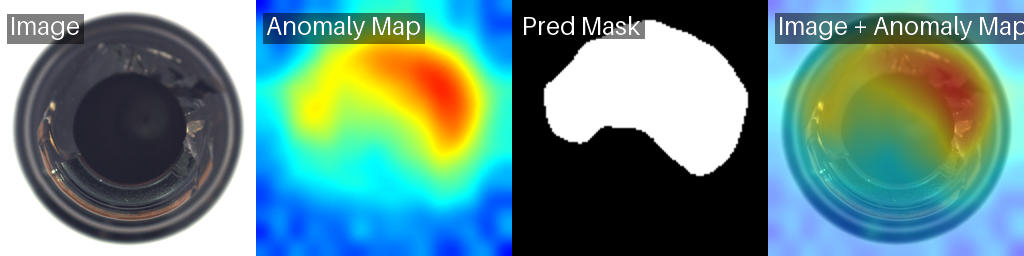

In [8]:
# ImageBatch에서 첫 ImageItem을 꺼내 Anomalib 내장 함수에 전달한다.
# 원본은 image_path에서 다시 읽으므로 정규화된 입력 텐서를 직접 그리지 않는다.
# 기본 이상맵 설정은 normalize=False여서 후처리된 [0,1] 점수 범위를 유지한다.
mvtec_visualization = visualize_image_item(
    mvtec_prediction.items[0],
    fields=['image', 'anomaly_map', 'pred_mask'],
    overlay_fields=[('image', ['anomaly_map'])],
)
display(mvtec_visualization)


## 6. 학습한 모델 저장하고 불러오기

매번 학습하지 않도록 정상 특징과 후처리 상태를 체크포인트로 저장한다. `weights_only=True`는 추론에 필요한 상태를 저장하고 옵티마이저 상태는 제외한다. 정확한 학습 재개용 파일과는 구분한다.

`Patchcore.load_from_checkpoint`로 모델을 복원한 뒤, 새 Engine에서 같은 이미지를 검사한다. `pre_trained=False`는 복원 전에 사전학습 가중치를 다시 준비하지 않게 한다. 실제 가중치는 저장된 체크포인트에서 읽는다. 직접 생성한 신뢰할 수 있는 체크포인트를 사용한다.


In [9]:
checkpoint_path = RESULTS / 'mvtecad_patchcore.ckpt'
mvtec_engine.trainer.save_checkpoint(checkpoint_path, weights_only=True)

restored_model = Patchcore.load_from_checkpoint(checkpoint_path, pre_trained=False)
restored_engine = NotebookEngine(default_root_dir=RESULTS / 'restored')
restored_prediction = restored_engine.predict(
    model=restored_model, data_path=image_path, return_predictions=True,
)[0]

torch.testing.assert_close(restored_prediction.pred_score, mvtec_prediction.pred_score)
print('저장 위치:', checkpoint_path)
print('복원한 모델의 예측 점수가 일치합니다.')


/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:210: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


HPU available: False, using: 0 HPUs


ckpt_path is not provided. Model weights will not be loaded.


Predicting: |          | 0/? [00:00<?, ?it/s]

저장 위치: C:/anomalib_lab/results/patchcore_usage/mvtecad_patchcore.ckpt
복원한 모델의 예측 점수가 일치합니다.


## 7. hazelnut_toy 내려받기

사용자 데이터 실습에는 Anomalib이 제공하는 **hazelnut_toy**를 사용한다. 약 6.4MB의 작은 데이터로, 실제 프로젝트에서 정상·이상·마스크 폴더를 연결하는 방법을 익히기에 적합하다.

```text
datasets/hazelnut_toy/
├── good/          정상 34장
├── crack/         균열 5장
├── colour/        색상 이상 17장
├── mask/crack/    균열 정답 마스크
├── mask/colour/   색상 이상 정답 마스크
└── LICENSE
```

`download_and_extract`는 다운로드, 체크섬 확인, 압축 해제를 수행한다. `hashsum`에는 배포 파일에서 직접 계산한 SHA-256을 사용한다. 포함된 `LICENSE`는 **CC BY-SA 4.0**이며, 앞선 MVTec AD 원본의 라이선스와 구분해 확인한다.


In [10]:
if not (DATA / 'hazelnut_toy/good').is_dir():
    download_and_extract(DATA, DownloadInfo(
        name='hazelnut_toy',
        url='https://github.com/open-edge-platform/anomalib/releases/download/hazelnut_toy_dataset/hazelnut_toy.zip',
        hashsum='c286c4c3e3924442bfe5ed549699b398f910531ec318c729bb6c25917cfad56e',
    ))
print('준비된 폴더:', DATA / 'hazelnut_toy')


준비된 폴더: C:/anomalib_lab/datasets/hazelnut_toy


## 8. Folder로 사용자 데이터 연결하기

`MVTecAD`는 정해진 폴더 구조를 알고 있지만, `Folder`는 어떤 폴더에 정상·이상·마스크가 있는지 직접 지정해야 한다.

| 인자 | 이 예제의 값 | 역할 |
|---|---|---|
| `normal_dir` | `good` | 정상 학습 이미지 |
| `abnormal_dir` | `crack`, `colour` | 이상 평가 이미지 |
| `mask_dir` | `mask/crack`, `mask/colour` | 이상 이미지와 대응하는 정답 마스크 |
| `normal_split_ratio` | `0.2` | 정상 이미지 중 일부를 평가용으로 분리 |
| `val_split_ratio` | `0.5` | 평가 자료를 검증·시험으로 분할 |

이 데이터에는 정상 시험 폴더가 따로 없으므로 `good`의 일부를 평가용으로 남긴다. 분할 후 학습은 정상 28장, 검증과 시험은 각각 정상 3장·이상 11장이다. `mask_dir`를 제공하므로 이미지·픽셀 평가를 함께 수행할 수 있다. 이미지 판정만 필요한 내 데이터에서는 `mask_dir`를 생략할 수 있다.


In [11]:
custom_data = Folder(
    name='hazelnut_toy',
    root=DATA / 'hazelnut_toy',
    normal_dir='good',
    abnormal_dir=['crack', 'colour'],
    mask_dir=['mask/crack', 'mask/colour'],
    normal_split_ratio=0.2,
    val_split_mode='from_test',
    val_split_ratio=0.5,
    train_batch_size=4,
    eval_batch_size=4,
    num_workers=0,
    seed=42,
)
custom_data.setup()

pd.Series({
    '정상 학습 이미지': len(custom_data.train_data),
    '검증 이미지': len(custom_data.val_data),
    '시험 이미지': len(custom_data.test_data),
}, name='hazelnut_toy 영상 수')


정상 학습 이미지    28
검증 이미지       14
시험 이미지       14
Name: hazelnut_toy 영상 수, dtype: int64

## 9. 사용자 데이터로 학습·평가·추론하기

검사 대상이 병에서 헤이즐넛으로 바뀌었으므로 **새 PatchCore 모델**을 만든다. 병의 정상 특징을 그대로 사용하지 않고, 헤이즐넛의 정상 특징을 새 메모리 뱅크에 모은다. 전처리와 모델 설정은 앞 실습과 같다.

바뀐 부분은 DataModule이다. `fit`, `test`, `predict`의 호출 방식은 그대로 유지된다.


In [12]:
custom_model = Patchcore(
    backbone='resnet18',
    coreset_sampling_ratio=0.01,
    pre_processor=Patchcore.configure_pre_processor(image_size=(128, 128)),
    visualizer=False,
)
custom_engine = NotebookEngine(default_root_dir=RESULTS / 'hazelnut_toy')
custom_engine.fit(model=custom_model, datamodule=custom_data)

custom_metrics = custom_engine.test(model=custom_model, datamodule=custom_data, verbose=False)
pd.Series(custom_metrics[0], name='hazelnut_toy 시험 성능')


/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:210: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


HPU available: False, using: 0 HPUs


/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:751: Checkpoint directory /home/claude/w11/C:/anomalib_lab/results/patchcore_usage/hazelnut_toy/Patchcore/hazelnut_toy/latest/weights/lightning exists and is not empty.
/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/core/optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer

  | Name           | Type           | Params | Mode 
----------------------------------------------------------
0 | pre_processor  | PreProcessor   | 0      | train
1 | post_processor | PostProcessor  | 0      | train
2 | evaluator      | Evaluator      | 0      | train
3 | model          | PatchcoreModel | 2.8 M  | train
----------------------------------------------------------
2.8 M     Trainable params
0         Non-trainable params
2.8 M     Total params
11.131    Total estimated model params size (MB)
19        Modules in train mode
69  

/home/claude/.venv11/lib/python3.11/site-packages/lightning/pytorch/loops/fit_loop.py:527: Found 69 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


... (4 outputs left out)

`Trainer.fit` stopped: `max_epochs=1` reached.


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor


Testing: |          | 0/? [00:00<?, ?it/s]

image_AUROC      1.000000
image_F1Score    0.842105
pixel_AUROC      0.918044
pixel_F1Score    0.307901
Name: hazelnut_toy 시험 성능, dtype: float64

ckpt_path is not provided. Model weights will not be loaded.


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor


Predicting: |          | 0/? [00:00<?, ?it/s]

이상 점수: 0.8509254455566406
이상 판정: True


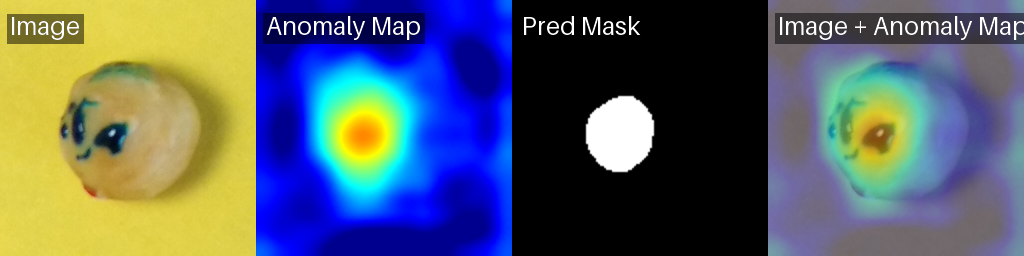

In [13]:
custom_image_path = custom_data.test_data.samples.query('label_index == 1').iloc[0].image_path
custom_prediction = custom_engine.predict(
    model=custom_model,
    data_path=custom_image_path,
    return_predictions=True,
)[0]

print('이상 점수:', float(custom_prediction.pred_score[0].cpu()))
print('이상 판정:', bool(custom_prediction.pred_label[0].cpu()))

# 사용자 데이터도 같은 내장 함수와 표시 설정을 사용한다.
custom_visualization = visualize_image_item(
    custom_prediction.items[0],
    fields=['image', 'anomaly_map', 'pred_mask'],
    overlay_fields=[('image', ['anomaly_map'])],
)
display(custom_visualization)

custom_engine.trainer.save_checkpoint(RESULTS / 'hazelnut_toy_patchcore.ckpt', weights_only=True)


`MVTecAD`와 `Folder`는 데이터를 읽는 방법이 다르지만, 모델과 Engine을 사용하는 흐름은 같다. 실제 이미지 폴더를 사용할 때는 `root`, `normal_dir`, `abnormal_dir`, `mask_dir`를 자신의 구조에 맞게 지정한다.

hazelnut_toy는 사용법을 배우는 작은 예제다. 시험 정상 이미지가 3장뿐이므로 오분류 한 장의 영향이 크다. 또한 병과 헤이즐넛은 검사 대상·표본 수·결함 유형이 다르므로 두 데이터셋의 지표 차이를 모델의 우열로 해석하지 않는다.


## 참고 자료

- [Anomalib 2.2.0 공식 저장소](https://github.com/open-edge-platform/anomalib/tree/v2.2.0)
- [PatchCore API](https://anomalib.readthedocs.io/en/v2.2.0/markdown/guides/reference/models/image/patchcore.html)
- [Anomalib 내장 시각화](https://anomalib.readthedocs.io/en/v2.2.0/markdown/guides/how_to/visualization/visualize_image.html)
- [사용자 데이터와 hazelnut_toy 공식 안내](https://anomalib.readthedocs.io/en/v2.2.0/markdown/guides/how_to/data/custom_data.html)
- [MVTec AD 원본 설명과 이용 조건](https://www.mvtec.com/research-teaching/datasets/mvtec-ad)
- [PyTorch 버전별 설치 명령](https://pytorch.org/get-started/previous-versions/)

이 노트북은 **Anomalib 2.2.0 / PyTorch 2.5.1 / Python 3.11** 기준이다. 다른 버전의 문서에는 인자나 기본 동작의 차이가 있을 수 있다.


## 📝 [11주차 실습 수행 결과 정리] Anomalib · PatchCore

**실행 환경:** Python 3.11 / Anomalib 2.2.0 / PyTorch 2.5.1(CPU, 2코어) — 노트북 지정 버전과 동일. 원본 코드 셀은 수정하지 않고 위에서부터 그대로 실행함(전체 약 23초, 데이터 캐시 후 기준).

### 1. 노트북 실행 결과 (교수님 출력과 비교)

| 항목 | 내 실행 (CPU) | 교수님 출력 (GTX 1650 Ti) |
|---|---|---|
| bottle 분할 (학습/검증/시험) | 209 / 41 / 42 | 209 / 41 / 42 (동일) |
| bottle image AUROC / F1 | 0.969 / 0.969 | 0.975 / 0.984 |
| bottle pixel AUROC / F1 | 0.961 / 0.608 | 0.961 / 0.604 |
| bottle 예측 이미지 점수 | 1.000 (이상) | 0.966 (이상) |
| 체크포인트 저장·복원 후 점수 일치 | 통과 | 통과 |
| hazelnut_toy 분할 | 28 / 14 / 14 | 28 / 14 / 14 (동일) |
| hazelnut image AUROC / F1 | 1.000 / 0.842 | 1.000 / 0.900 |
| hazelnut pixel AUROC / F1 | 0.918 / 0.308 | 0.925 / 0.290 |

- 수치가 조금씩 다른 이유: PatchCore의 coreset 선택은 무작위 투영을 쓰므로 난수에 따라 메모리 뱅크가 달라진다. 노트북은 `seed_everything(42)`를 맨 처음 한 번만 호출하므로 hazelnut 학습은 앞선 bottle 실행이 소비한 난수 상태를 이어받고, CPU·GPU의 난수 생성기도 다르다.
- 시드 0~9로 10회 반복(같은 설정): bottle image F1 **0.979 ± 0.008**(0.968~0.984), hazelnut image F1 **0.868 ± 0.072**(0.706~0.952). 교수님 값과 내 값은 모두 이 범위 안에 있다. 시험 영상이 42장·14장뿐이라 한 장의 판정이 바뀌면 F1이 크게 흔들린다.
- 예측 점수 1.000은 정규화 후 [0,1]로 잘린(clip) 값이다. 검증 데이터에서 본 점수 범위를 넘으면 모두 1.0이 되므로 "확률 100%"로 해석하면 안 된다.

### 2. bottle — 어디서 틀리는가

※ 2·3절은 같은 설정을 별도 스크립트로 다시 돌려(데이터셋마다 시드 42로 재설정) 시험 영상별 점수·마스크를 뽑은 결과. bottle은 노트북과 지표가 완전히 같고, hazelnut은 image 지표는 같으며 pixel 지표만 조금 다르다(AUROC 0.931 / F1 0.248).

| 시험 영상 종류 | 장수 | 이상 판정 | 점수 범위 | 평균 IoU |
|---|---|---|---|---|
| broken_large | 14 | 14 | 0.75~1.00 | 0.44 |
| broken_small | 9 | 9 | 0.68~1.00 | 0.42 |
| contamination | 9 | **8** | 0.44~1.00 | 0.46 |
| good | 10 | **1 (과검출)** | 0.45~0.52 | — |

- 오판은 2장뿐: `contamination/019`(점수 0.444, 미검출)와 `good/000`(0.518, 과검출). 둘 다 임계값 0.5 바로 옆이다. 정상 이미지 점수(0.45~0.52)가 임계값에 붙어 있어 여유(margin)가 거의 없다.
- **pixel AUROC 0.96인데 pixel F1이 0.61인 이유:** 결함 픽셀은 전체의 6.5%뿐이다. 임계값 0.5에서 정밀도 0.47 / 재현율 0.85로, 결함은 대부분 덮지만 **결함보다 넓게 칠한다**(위 시각화의 Pred Mask도 실제 파손보다 크다). 128px 입력 → ResNet18 특징맵 16×16을 업샘플하고 가우시안 블러를 거치므로 경계가 뭉개진다. 전체 IoU 0.44. 픽셀 임계값을 바꿔도 최고 F1은 0.61로 거의 같아 → 임계값이 아니라 **해상도 문제**다.

### 3. hazelnut_toy — AUROC 1.0인데 왜 F1은 0.84인가

| 시험 영상 종류 | 장수 | 이상 판정 | 점수 범위 | 평균 IoU |
|---|---|---|---|---|
| colour | 7 | 7 | 0.55~0.91 | 0.35 |
| crack | 4 | **1** | 0.37~0.60 | **0.01** |
| good | 3 | 0 | 0.10~0.17 | — |

- image AUROC 1.0 = 모든 이상 점수가 모든 정상 점수보다 높다(순위는 완벽). 그런데 균열 4장 중 3장이 임계값 아래(0.37~0.50)라 놓친다. **점수는 맞는데 임계값이 틀린 경우**다.
- 원인: `val_split_ratio=0.5` 분할 결과 **검증 데이터에 crack이 1장뿐**(colour 10, good 3). 임계값이 거의 colour만 보고 정해졌는데, colour는 점수가 높고 crack은 낮다. 정상 최고 0.17과 crack 최저 0.37 사이에 임계값을 두면 전부 맞출 수 있다.
- 균열은 가늘어서 128px에서 IoU 0.01 → 위치는 사실상 못 찾고 있다. 픽셀 재현율 0.17.
- 강의자료 58쪽 실패 유형 중 "작은 결함 미검출 → 해상도·특징 크기 부족(입력·방법 설계)"과 "운영 규칙(임계값)" 두 가지가 동시에 나타난 사례.

### 4. 추가 실험 — 해상도·백본 비교 (시드 3회 평균, CPU)

| 데이터 | 설정 | image AUROC | image F1 | pixel AUROC | pixel F1 | 학습 시간 |
|---|---|---|---|---|---|---|
| bottle | 128px · ResNet18 (노트북) | 0.984 | 0.979 | 0.961 | 0.604 | 12초 |
| bottle | 128px · WideResNet50 | 0.998 | 0.984 | 0.967 | 0.638 | 19초 |
| bottle | 256px · ResNet18 | **1.000** | **1.000** | **0.975** | **0.640** | **243초** |
| hazelnut | 128px · ResNet18 (노트북) | 1.000 | 0.879 | 0.917 | 0.274 | 1초 |
| hazelnut | 128px · WideResNet50 | 1.000 | **1.000** | 0.916 | 0.353 | 3초 |
| hazelnut | 256px · ResNet18 | 1.000 | 0.778 | 0.926 | 0.272 | 3초 |

- bottle은 해상도를 올리면 완벽해지지만, 패치 수가 4배(메모리 뱅크 535 → 2,140개)가 되면서 coreset 선택 시간이 약 20배 늘었다. CPU에서는 128px·WideResNet50이 비용 대비 효율이 가장 좋다.
- hazelnut은 해상도를 올려도 F1이 오히려 떨어졌다(0.78) → 문제는 해상도보다 **검증 데이터 구성(crack 1장)**이다. WideResNet50은 3회 모두 F1 1.0이었다(특징이 더 풍부해 crack 점수가 올라감).
- 참고: WideResNet50·256px(Anomalib 기본 설정)은 학습 특징이 약 86만 패치 × 1,536차원이라 이 환경(RAM 7.6GB)에서 메모리 5GB를 넘겨 중단함. GPU PC에서 확인 권장.

### 5. 정리

- `MVTecAD`·`Folder` 어느 쪽이든 `fit → test → predict → 체크포인트 저장/복원` 흐름은 같고, 노트북 그대로 문제없이 동작했다.
- **AUROC는 "점수 순위", F1은 "현재 임계값의 판정"**을 평가한다. hazelnut 결과가 그 차이를 가장 분명하게 보여준다: 순위는 완벽해도 임계값을 정한 검증 데이터가 결함 종류를 대표하지 못하면 현장에서는 결함을 놓친다.
- 실무 적용 시: ① 검증 데이터에 결함 유형별로 충분한 장수 확보(층화 분할), ② 작은·가는 결함은 입력 해상도 또는 백본 강화, ③ 픽셀 마스크는 결함보다 넓게 나오므로 면적 기준 판정 시 보정 필요, ④ 시험 데이터 수가 적으면 여러 시드로 반복해 편차까지 보고할 것.
